#### Exploratory Data Analysis - Trend and Multivariate Analysis
Here I'll perform trend and multivariate analysis to get the insights from the cleaned data.

#### Step-0: Setup

In [2]:
# Imports and load
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Loading the data with dates (parse_dates tells which columns are dates)
df=pd.read_csv("../data/cleaned/charging_clean.csv", parse_dates=['StartDatetime','EndDatetime'])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72088 entries, 0 to 72087
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   UserID          72088 non-null  int64         
 1   ChargerID       72088 non-null  int64         
 2   ChargerCompany  72088 non-null  int64         
 3   Location        72088 non-null  object        
 4   ChargerType     72088 non-null  int64         
 5   StartDatetime   72088 non-null  datetime64[ns]
 6   EndDatetime     72088 non-null  datetime64[ns]
 7   Duration        72088 non-null  int64         
 8   Demand          72088 non-null  float64       
dtypes: datetime64[ns](2), float64(1), int64(5), object(1)
memory usage: 5.0+ MB


In [4]:
# Creating time columns (needed for few questions in the analysis)
df['Hour']=df['StartDatetime'].dt.hour
df['Month']=df['StartDatetime'].dt.month
df['Weekday']=df['StartDatetime'].dt.day_name()
df['Date']=df['StartDatetime'].dt.date
df['IsWeekend']=df['StartDatetime'].dt.day_of_week>=5
df.head()

,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDatetime,EndDatetime,Duration,Demand,Hour,Month,Weekday,Date,IsWeekend
0,0,1,1,hotel,0,2022-09-15 20:54:00,2022-09-15 23:59:00,185,20.36,20,9,Thursday,2022-09-15,False
1,0,1,1,hotel,0,2022-09-14 20:01:00,2022-09-14 21:31:00,90,10.19,20,9,Wednesday,2022-09-14,False
2,0,1,1,hotel,0,2022-09-14 18:54:00,2022-09-14 19:54:00,60,6.78,18,9,Wednesday,2022-09-14,False
3,0,1,1,hotel,0,2022-09-29 18:32:00,2022-09-30 00:16:00,344,37.65,18,9,Thursday,2022-09-29,False
4,0,1,1,hotel,0,2022-09-25 19:30:00,2022-09-26 00:30:00,300,33.81,19,9,Sunday,2022-09-25,True


#### Step-1: Trend Analysis

> **Q9. How does total daily and monthly demand change over the year? Is there a trend or a weekly pattern?**

In [5]:
# Month wise total demand
df['YearMonth']= df['StartDatetime'].dt.to_period('M')
monthly_total= df.groupby('YearMonth')['Demand'].sum().iloc[1:]
monthly_total

YearMonth
2021-10     64593.97
2021-11     71454.90
2021-12     84529.75
2022-01    109126.64
2022-02    102620.47
2022-03    103519.71
2022-04    104150.13
2022-05    115200.06
2022-06    117408.10
2022-07    139404.74
2022-08    142976.92
2022-09    111017.58
Freq: M, Name: Demand, dtype: float64

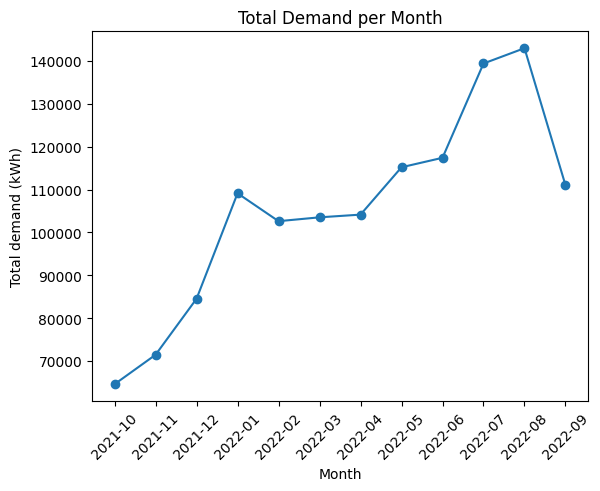

In [ ]:
# Plotting monthly demand chart
plt.plot(monthly_total.index.astype(str), monthly_total.values, marker='o')
plt.title('Total Demand per Month')
plt.xlabel('Month')
plt.ylabel('Total demand (kWh)')
plt.xticks(rotation=45)
plt.show()

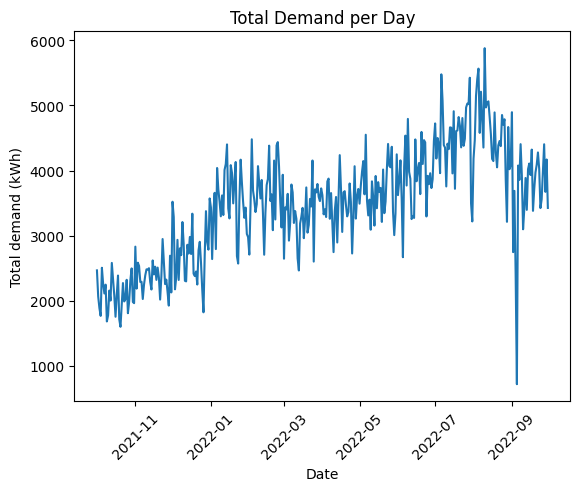

In [7]:
# Plotting daily demand chart
daily_total= df.groupby('Date')['Demand'].sum().iloc[1:]
plt.plot(daily_total.index, daily_total.values)
plt.title('Total Demand per Day')
plt.xlabel('Date')
plt.ylabel('Total demand (kWh)')
plt.xticks(rotation=45)
plt.show()

#### Observations: 
1. Daily demand rises over the year, from 2000–2500 kWh/day in Oct–Dec 2021 to about 3500 from Jan 2022 and about 4500 in Jul–Aug 2022. 
2. The line goes up and down every few days. As seen in Q6, weekdays (highest on Thursday) are busier than weekends (lowest on Sunday), so part of this up and down is a weekly pattern.
3. It means demand is growing over time, with a weekly pattern.

> **Q10. Are some users and chargers used much more than others? Are there underused chargers?**
11. How does demand vary by location and hour together? For example do hotels peak at night and companies during the day?
12. Does the effect of charger type on demand change across locations?
13. Which variables are most correlated with demand?

In [13]:
# Top users
user_sessions = df['UserID'].value_counts().sort_values(ascending=False)
user_sessions.head()

UserID
0      31210
31       352
95       348
179      338
40       323
Name: count, dtype: int64

In [15]:
# Checking UserId 0
(df['UserID']==0).mean()*100, df[df['UserID']==0]['ChargerID'].nunique()

(np.float64(43.294306958162245), 309)

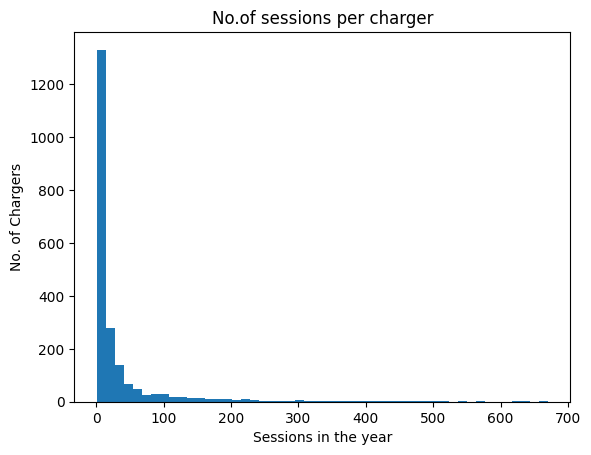

In [18]:
charger_sessions= df['ChargerID'].value_counts()
plt.hist(charger_sessions, bins=50)
plt.title('No.of sessions per charger')
plt.xlabel('Sessions in the year')
plt.ylabel('No. of Chargers')
plt.show()

In [22]:
# Busy vs Underused chargers
charger_sessions.describe(), (charger_sessions<=5).sum()

(count    2115.000000
 mean       34.084161
 std        74.847145
 min         1.000000
 25%         3.000000
 50%         9.000000
 75%        26.000000
 max       670.000000
 Name: count, dtype: float64,
 np.int64(804))

#### Observations: 
1. UserID 0 has 31,210 sessions (43% of all data) at 309 different chargers, so it's likely for unregistered users.. 
2. Among real users, half charged only 1–3 times, while a few charged over 300 times. 
3. For chargers, the median is only 9 sessions in the year. The busiest had about 670, while 804 chargers (38%) had 5 or fewer sessions.